# A04-DB — DBSCAN trên RFM (Standard + PCA 95%)

Thí nghiệm **A04-DB** (người chạy: Nguyên) theo chiến lược model. So với A01, **chỉ đổi ngưỡng PCA từ 90% lên 95%**: làm sạch → RFM → StandardScaler → PCA giữ ≥ 95% phương sai → DBSCAN.

Lưới eps × min_samples, điều kiện chọn và dữ liệu giữ nguyên như A01-DB (An) để hai thí nghiệm so sánh được. Theo bảng chiến lược: nếu số PC bằng A01 thì ghi *tương đương*; notebook này kiểm lại bằng số thay vì chỉ suy luận.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
PCA_VAR = 0.95                      # A04: giữ ít nhất 95% phương sai (thay đổi duy nhất so với A01)
PCA_VAR_A01 = 0.90                  # ngưỡng của A01 — chỉ để đối chiếu
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]   # giống A01-DB
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # giống A01-DB
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01-DB, A02-KM), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4.327 khách, 3 biến RFM, không thiếu giá trị, `CustomerID` không trùng. Phân phối lệch phải mạnh (Monetary median 657,9, max 278.748; Frequency median 2, max 206). Đây là file làm sạch cũ của nhóm, không phải RFM tính thẳng từ raw (xem lưu ý chi tiết ở A02-KM): A01-DB, A02-KM và A04-DB so sánh được với nhau vì cùng một file.

## Chuẩn hóa và PCA giữ 95% phương sai

DBSCAN dựa trên khoảng cách nên phải scale. Không dùng log1p vì thuộc nhánh B.

In [3]:
X_scaled = StandardScaler().fit_transform(X)

cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
n_pc_a01 = int(np.searchsorted(cum, PCA_VAR_A01) + 1)

Z = PCA(n_components=n_pc, svd_solver="full").fit_transform(X_scaled)               # A04
Z_a01 = PCA(n_components=n_pc_a01, svd_solver="full").fit_transform(X_scaled)       # A01 dựng lại
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: A04 (95%) = {n_pc} | A01 (90%) = {n_pc_a01} | tổng số biến = {len(FEATURES)}")
print("Không gian đầu vào A04 trùng A01:", bool(Z.shape == Z_a01.shape and np.allclose(Z, Z_a01)))

Phương sai tích lũy: [0.5638 0.8655 1.    ]
Số PC giữ lại: A04 (95%) = 3 | A01 (90%) = 3 | tổng số biến = 3
Không gian đầu vào A04 trùng A01: True


**Nhận xét:** 2 PC chỉ giữ 86,55% phương sai, nên cả ngưỡng 90% (A01) lẫn 95% (A04) đều phải giữ đủ 3/3 PC. Hai không gian đầu vào trùng nhau từng điểm, nên về lý thuyết A04-DB ≡ A01-DB. Các bước sau chạy đủ lưới để kiểm bằng số.

## Chọn eps bằng đồ thị k-distance

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó, giống cách DBSCAN đếm), sắp xếp tăng dần. Điểm bẻ cong mạnh gợi ý eps.

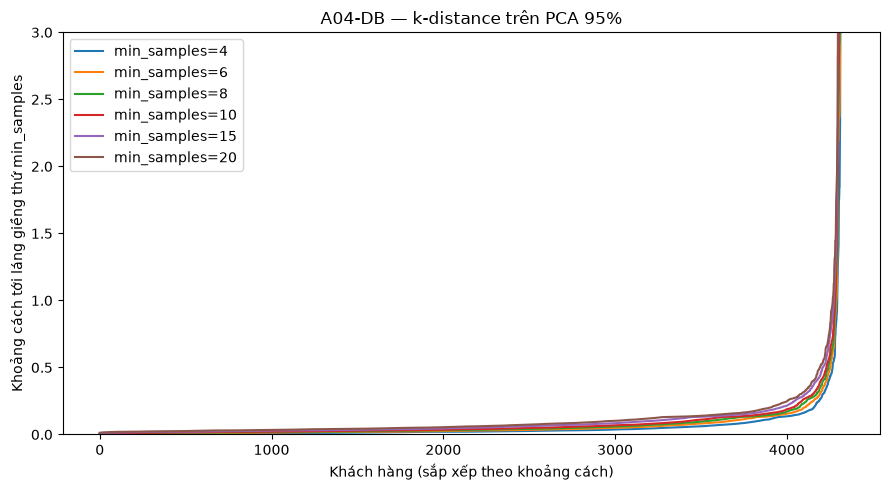

,4,6,8,10,15,20
P50,0.021,0.029,0.034,0.040,0.051,0.060
P90,0.112,0.135,0.145,0.157,0.180,0.199
P95,0.168,0.206,0.243,0.270,0.302,0.330
P99,0.742,0.898,1.002,1.073,1.272,1.443


In [4]:
kdist = {}
for ms in MIN_SAMPLES_GRID:
    d = NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]
    kdist[ms] = np.sort(d)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kdist.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("A04-DB — k-distance trên PCA 95%")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "k_distance.png", dpi=150)
plt.show()

pd.DataFrame({ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99]) for ms, d in kdist.items()},
             index=["P50", "P90", "P95", "P99"]).round(3)

**Nhận xét:** Khoảng cách rất nhỏ ở phần lớn khách (P50 chỉ 0,02–0,06; P95 0,17–0,33) rồi tăng vọt ở đuôi (P99 0,74–1,44). Phần lớn khách dồn dày quanh một vùng, khoảng 1–5% là điểm xa; đồ thị không có khuỷu rõ nên lưới eps phủ cả vùng nhỏ (0,1–0,3) lẫn vùng đuôi (≥ 1,0).

## Quét lưới eps × min_samples

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [5]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Zs), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Zs[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Zs[mask], labels[mask]), 4)
    return row, labels

pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID]
runs = [run_dbscan(Z, e, m) for e, m in pairs]
grid = pd.DataFrame([r for r, _ in runs])
labels_a04 = {p: l for p, (_, l) in zip(pairs, runs)}
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
print("Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách:",
      int(((grid["n_clusters"] >= 2) & (grid["largest_pct"] < 90)).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(10)

Số cấu hình đã chạy: 54
Số cấu hình có >= 2 cụm: 14
Số cấu hình có >= 2 cụm và cụm lớn nhất < 90% khách: 6


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
7,4,1.5,3,0.42,99.40,4,0.8177,0.4046
2,4,0.3,2,2.29,97.53,8,0.6668,0.3041
11,6,0.3,2,2.43,97.43,6,0.6596,0.2909
29,10,0.3,2,2.96,96.81,10,0.5761,0.3746
37,15,0.2,2,5.57,94.01,18,0.4542,0.4846
1,4,0.2,5,3.35,95.98,4,0.3314,0.5449
19,8,0.2,2,4.41,95.40,8,0.3200,0.5991
10,6,0.2,3,3.95,95.68,6,0.3167,0.5237
27,10,0.1,16,15.65,31.82,8,-0.2015,1.8466
45,20,0.1,10,24.17,31.78,30,-0.2436,2.1182


**Nhận xét:** Chỉ 14/54 cấu hình có ≥ 2 cụm. 6 cấu hình có cụm lớn nhất < 90% đều ở eps = 0,1, nhưng nhiễu 9–24% và Silhouette âm (−0,20 đến −0,32) — chia vụn nên không dùng được. Các cấu hình còn lại đều có một cụm chiếm ≥ 94% khách: DBSCAN trên RFM thô chủ yếu tách ngoại lai, không chia khách thành các nhóm cân đối.

## Chọn cấu hình

Cùng quy tắc A01-DB (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, chọn **Silhouette cao nhất** trong các cấu hình thỏa.

In [6]:
valid = grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Cấu hình được chọn:")
print(best.to_string())

Cấu hình được chọn:
min_samples     4.0000
eps             1.5000
n_clusters      3.0000
noise_pct       0.4200
largest_pct    99.4000
smallest        4.0000
silhouette      0.8177
dbi             0.4046


**Nhận xét:** Chọn `eps = 1,5`, `min_samples = 4`: 3 cụm, nhiễu 0,42% (18 khách), Silhouette 0,8177, DBI 0,4046. Silhouette cao vì khối khách phổ thông (99,4%) nằm rất xa vài cụm nhỏ (4 khách/cụm), không phải vì phân khúc tốt; không nên so con số này trực tiếp với các mô hình chia cụm cân đối.

## Đối chiếu A01-DB

Dựng lại A01 (PCA 90%) và chạy đúng lưới 54 cấu hình, rồi so với A04 theo từng cấu hình: ARI giữa hai bộ nhãn (kể cả nhãn nhiễu −1), và bảng kết quả của A01-DB do An đã lưu.

In [7]:
runs_a01 = [run_dbscan(Z_a01, e, m) for e, m in pairs]
grid_a01 = pd.DataFrame([r for r, _ in runs_a01])
ari = [adjusted_rand_score(labels_a04[p], l) for p, (_, l) in zip(pairs, runs_a01)]
n_same = int(sum(a == 1.0 for a in ari))
print(f"Số cấu hình cho nhãn y hệt A01 (ARI = 1,0): {n_same}/{len(pairs)}")
print("Bảng lưới A04 == bảng lưới A01 dựng lại:", bool(grid.equals(grid_a01)))

# Đối chiếu thêm với kết quả A01-DB do An lưu
an_grid = pd.read_csv(find("notebooks/03_clustering_eval/16-11-2026_an_dbscan_a01/data/dbscan_a01_grid.csv"))
print("Bảng lưới A04 == bảng lưới A01-DB của An:", bool(grid.round(4).astype(float).equals(an_grid.round(4).astype(float))))

Số cấu hình cho nhãn y hệt A01 (ARI = 1,0): 54/54
Bảng lưới A04 == bảng lưới A01 dựng lại: True
Bảng lưới A04 == bảng lưới A01-DB của An: True


**Nhận xét:** **A04-DB trùng hoàn toàn A01-DB**: cả 54/54 cấu hình cho nhãn y hệt (ARI = 1,0), và bảng lưới khớp từng ô với bảng An đã lưu. Đổi ngưỡng PCA 90% → 95% không đổi gì vì cả hai đều giữ đủ 3 PC. Theo bảng chiến lược, ghi là *tương đương A01*.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary của nhóm.

In [8]:
labels = labels_a04[(float(best["eps"]), int(best["min_samples"]))]
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
-1,18,3.0,61.0,63643.2,0.4,19.2
0,4301,52.0,2.0,654.7,99.4,76.5
1,4,3.0,54.0,35907.5,0.1,1.6
2,4,4.0,46.0,56282.3,0.1,2.7


**Nhận xét:** Cụm 0 (4.301 khách, 99,4%) có Recency 52, Frequency 2, Monetary 654,7 — gần trung vị toàn bộ, đóng góp 76,5% Monetary. Cụm 1, cụm 2 (mỗi cụm 4 khách) và nhóm nhiễu (18 khách) tổng 26 khách (0,6%): mua rất gần đây (Recency 3–4 ngày), Frequency 46–61, Monetary 35.907–63.643, chiếm 23,5% Monetary. Đây là nhóm khách ngoại lai cực lớn, giống nhóm 24 khách mà K-Means (A02-KM) tách ra.

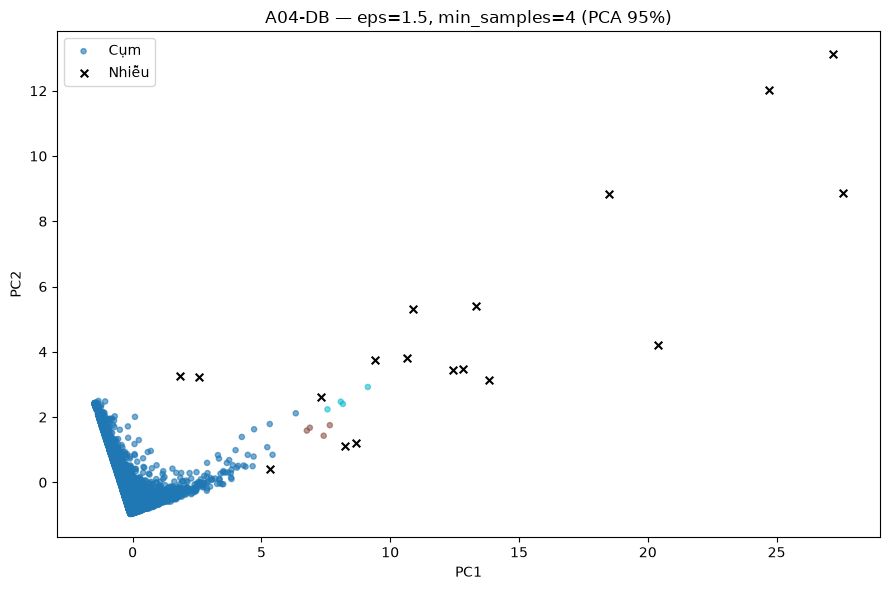

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"A04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (PCA 95%)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150)
plt.show()

**Nhận xét:** Gần như toàn bộ khách dồn thành một khối ở gốc tọa độ, còn các cụm nhỏ và điểm nhiễu rải dọc đuôi PC1 — DBSCAN chỉ tách phần đuôi ngoại lai.

## Lưu kết quả

In [10]:
grid.to_csv(OUT / "dbscan_a04_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_a04_labels.csv", index=False)
params = {"experiment": "A04-DB", "features": FEATURES, "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc,
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "equivalent_to": f"A01-DB (PCA 90% và 95% đều giữ {n_pc}/3 PC; {n_same}/{len(pairs)} cấu hình ARI = 1.0)"}
json.dump(params, open(OUT / "dbscan_a04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_a04_grid.csv', 'dbscan_a04_labels.csv', 'dbscan_a04_params.json']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng cấu hình, bảng cụm), chuyển các cột cho DBSCAN.

In [11]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "DBSCAN_A04"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None):
    ws[cell] = value
    ws[cell].font = B if bold else Font(name="Calibri")
    if fmt: ws[cell].number_format = fmt

e_best, m_best = float(best["eps"]), int(best["min_samples"])
put("A1", "THÍ NGHIỆM DBSCAN — A04 (RFM, Standard, PCA 95%)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", f"Đã chạy xong; {n_same}/{len(pairs)} cấu hình trùng A01-DB (ARI = 1,0) nên tương đương A01")

for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary"), ("Dữ liệu train", "Z (StandardScaler + PCA 95%)"),
        ("eps được chọn", e_best), ("min_samples được chọn", m_best),
        ("Quy tắc chọn", "≥ 2 cụm, nhiễu ≤ 5%, Silhouette lớn nhất"),
        ("Lưới", f"{len(EPS_GRID)} eps × {len(MIN_SAMPLES_GRID)} min_samples = {len(pairs)}")]
right = [("PCA", f"95% → {n_pc}/3 PC (phương sai {cum[n_pc-1]:.0%})"), ("Tổng khách hàng", int(len(X))),
         ("Số cụm (không tính nhiễu)", int(best["n_clusters"])), ("Nhiễu (%)", float(best["noise_pct"])),
         ("Khoảng cách", "Euclid (mặc định)"), ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

hdr = ["min_samples", "eps", "Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)", "Cụm nhỏ nhất (khách)", "Silhouette", "DBI", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(f"{c}12", v, bold=True)
multi = grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False)
for i, r in enumerate(multi.itertuples(), start=13):
    if r.eps == e_best and r.min_samples == m_best: note = "cấu hình được chọn"
    elif r.noise_pct > MAX_NOISE * 100: note = "loại: nhiễu > 5%"
    else: note = ""
    if r.silhouette < 0: note = (note + "; " if note else "") + "Silhouette âm (chia vụn)"
    vals = [int(r.min_samples), float(r.eps), int(r.n_clusters), float(r.noise_pct), float(r.largest_pct),
            int(r.smallest), float(r.silhouette), float(r.dbi), note]
    fmts = [None, "0.00", None, "0.00", "0.00", None, "0.0000", "0.0000", None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(f"{c}{i}", v, fmt=f)
put(f"A{13 + len(multi)}", f"Chỉ liệt kê {len(multi)}/{len(grid)} cấu hình có ≥ 2 cụm; các cấu hình còn lại chỉ có 1 cụm.")

r0 = 13 + len(multi) + 3
hdr2 = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)",
        "Monetary (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGH", hdr2): put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Nhiễu (ngoại lai)" if cl == -1 else "Khối chính" if p["customers"] == prof["customers"].max() else "Cụm nhỏ")
    put(f"A{j}", int(cl)); put(f"B{j}", nhom); put(f"C{j}", int(p["customers"]))
    put(f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(f"E{j}", float(p["Recency"]))
    put(f"F{j}", float(p["Frequency"])); put(f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(f"H{j}", float(p["Monetary_share_pct"]), fmt="0.00")

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu A01-DB (PCA 90%) trên toàn lưới", bold=True)
cmp_rows = [("Số PC giữ lại", f"A04: {n_pc} | A01: {n_pc_a01}"),
            ("Không gian đầu vào trùng nhau", "Có" if np.allclose(Z, Z_a01) else "Không"),
            ("Cấu hình có nhãn y hệt A01 (ARI = 1,0)", f"{n_same}/{len(pairs)}"),
            ("Bảng lưới khớp bảng A01-DB của An", "Có" if grid.round(4).astype(float).equals(an_grid.round(4).astype(float)) else "Không"),
            ("Kết luận", "A04-DB tương đương A01-DB")]
for j, (a, b) in enumerate(cmp_rows, start=r1 + 1):
    put(f"A{j}", a); put(f"E{j}", b)

for col, w in zip("ABCDEFGHI", [16, 22, 17, 19, 20, 21, 25, 22, 13]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"
wb.save("Working_details_DBSCAN_A04.xlsx")
print("Đã lưu Working_details_DBSCAN_A04.xlsx")

Đã lưu Working_details_DBSCAN_A04.xlsx


## Kết luận A04-DB

- **A04-DB ≡ A01-DB.** Với 3 biến RFM, PCA 90% và 95% đều giữ đủ 3 PC, nên không gian đầu vào của DBSCAN trùng nhau từng điểm; 54/54 cấu hình cho nhãn y hệt. Ghi *tương đương A01*, không cần thử thêm ngưỡng PCA.
- **Kết quả vẫn chỉ tách ngoại lai:** cấu hình được chọn (eps 1,5, min_samples 4) tách 26 khách (18 nhiễu + 2 cụm × 4 khách, 0,6%) khỏi khối 4.301 khách (99,4%). Các cấu hình chia nhỏ hơn thì vụn (Silhouette âm).
- **Nút thắt là phân phối lệch phải của RFM thô**, không phải PCA. Bước kế tiếp của DBSCAN là nhánh B (log1p), cụ thể B04-DB (log1p + MinMax).